# Ridge-Based Hybrids for an Offline Battery Digital Twin
## Reproducible held-out-cell evaluation
This notebook supports the consolidated manuscript. It downloads the original NASA PCoE archive linked by NASA, extracts B0005, B0006, B0007 and B0018, and reproduces every primary result. The earlier Kaggle and unified NASA work is preserved separately as exploratory history. NASA is not an untouched external validation set. The designated proposed model is Ridge plus Gradient Boosting residual correction; Ridge stacking is a comparator.

**Fixed experiment:** first 600 seconds of each discharge; no capacity or target-derived health proxy as input; one complete battery held out; base models trained with leave-one-training-cell-out predictions before fitting the Ridge meta-regressor. Residual strengths 0, 0.1, 0.25, 0.5 and 1 are selected by inner held-out training-cell MAE. Outer test scores are not used to tune those strengths. No current or future held-out capacity is fed to the predictor.

**Scope:** SOH estimation and an offline state-update prototype. RUL is evaluated at fixed origins against recorded 70% endpoints; the non-crossing cell is right-censored. There is no live BMS control, field failure prediction, or guaranteed safety outcome.

\[
y_{c,k}=100\frac{Q_{c,k}}{2\,\mathrm{Ah}},\qquad
\widehat y_{c,k}=b+\boldsymbol\beta^{\mathsf T}\widetilde{\mathbf p}_{c,k}.
\]
\[
z_{c,k}=(1-K)z_{c,k-1}+K\widehat y_{c,k},\quad K\in\{1,0.70,0.35\}.
\]


In [1]:
from pathlib import Path
import io, importlib.util, subprocess, sys, urllib.request, shutil, zipfile
needed = {'numpy':'numpy','pandas':'pandas','scipy':'scipy','sklearn':'scikit-learn','matplotlib':'matplotlib','joblib':'joblib'}
missing = [pkg for mod,pkg in needed.items() if importlib.util.find_spec(mod) is None]
if missing: subprocess.check_call([sys.executable,'-m','pip','install',*missing])
ROOT = Path('publication_study').resolve()
ROOT.mkdir(exist_ok=True)
NASA_URL = 'https://phm-datasets.s3.amazonaws.com/NASA/5.+Battery+Data+Set.zip'
if not all((ROOT/'cells'/f'{cell}.mat').exists() for cell in ['B0005','B0006','B0007','B0018']):
    archive = ROOT/'nasa_original.zip'
    if not archive.exists():
        with urllib.request.urlopen(NASA_URL,timeout=60) as source, archive.open('wb') as target:
            shutil.copyfileobj(source,target)
    with zipfile.ZipFile(archive) as z:
        member = next(n for n in z.namelist() if n.endswith('1. BatteryAgingARC-FY08Q4.zip'))
        with zipfile.ZipFile(io.BytesIO(z.read(member))) as inner:
            (ROOT/'cells').mkdir(exist_ok=True)
            for name in inner.namelist():
                if name.endswith(('.mat','.txt')):
                    (ROOT/'cells'/Path(name).name).write_bytes(inner.read(name))
print('NASA raw files ready:', ROOT/'cells')


NASA raw files ready: /workspace/scratch/1a4c28750ace/publication_study/cells


## Feature extraction, residual correction, stacking and grouped evaluation
The script exports per-cell and macro errors, frozen-model noise tests, synchronization sensitivity, threshold timing and RUL-origin results. R² is reported by cell and then averaged. Noise repeats are perturbation diagnostics, not independent battery replications.


## Proposed residual hybrid

\[\widehat{y}_{H,c,k}=f_{\mathrm{Ridge}}(\mathbf{x}_{c,k})+\lambda g_{\mathrm{GB}}(\mathbf{x}_{c,k}).\]

Correction strength is chosen by inner training-cell MAE from 0, 0.1, 0.25, 0.5 and 1.0. The boosting correction fits Ridge training residuals; its generalization is evaluated on excluded inner cells. This is additive residual learning, not Ridge stacking. Both methods are evaluated on the same outer held-out cells.


In [2]:
from pathlib import Path
import json,hashlib,time
import numpy as np,pandas as pd
from scipy.io import loadmat
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression,Ridge
from sklearn.ensemble import ExtraTreesRegressor,GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import joblib
OUT=ROOT/'results';OUT.mkdir(exist_ok=True)
CONFIG={'cells':['B0005','B0006','B0007','B0018'],'window_seconds':600,'capacity_reference_Ah':2.,'endpoint_Ah':1.4,'outer':'leave-one-cell-out','inner':'leave-one-cell-out','seed':42,'ridge_alpha':1.,'gains':[1.,.7,.35],'rul_origins':[40,80,120],'rul_window':20,'noise_repeats':20,'noise_sd':{'voltage_V':.01,'temperature_C':.5,'current_A':.01},'selection':'fixed parameters; residual strength selected inside outer training groups; exploratory NASA comparison' ,'residual_strengths':[0.,.1,.25,.5,1.]}
(OUT/'protocol.json').write_text(json.dumps(CONFIG,indent=2))
FEATURES=['cycle','v0','v60','v300','v600','vdrop','tmean','tmax','trise','imean','vslope']
def extract(c,k,noise=False,rng=None):
 d=c['data'];t=np.asarray(d['Time'],float).ravel();t=t-t[0]
 v=np.asarray(d['Voltage_measured'],float).ravel();temp=np.asarray(d['Temperature_measured'],float).ravel();cur=np.asarray(d['Current_measured'],float).ravel()
 ok=np.isfinite(t)&np.isfinite(v)&np.isfinite(temp)&np.isfinite(cur);t,v,temp,cur=t[ok],v[ok],temp[ok],cur[ok]
 ix=np.argsort(t);t,v,temp,cur=t[ix],v[ix],temp[ix],cur[ix]
 if len(t)<5 or t[-1]<600:return None
 ok=t<=600;t,v,temp,cur=t[ok],v[ok],temp[ok],cur[ok]
 if noise:v=v+rng.normal(0,.01,len(v));temp=temp+rng.normal(0,.5,len(temp));cur=cur+rng.normal(0,.01,len(cur))
 vs=np.interp([0,60,300,600],t,v)
 return dict(zip(FEATURES,[k,*vs,vs[0]-vs[-1],temp.mean(),temp.max(),temp[-1]-temp[0],np.abs(cur).mean(),np.polyfit(t,v,1)[0]]))
def data():
 rows=[];traces={};audit=[]
 for cell in CONFIG['cells']:
  p=next((ROOT/'cells').rglob(cell+'.mat'));cycles=loadmat(p,simplify_cells=True)[cell]['cycle'];k=0;excluded=0
  for c in cycles:
   if c['type']!='discharge':continue
   k+=1;f=extract(c,k)
   if f is None:excluded+=1;continue
   cap=float(c['data']['Capacity']);f.update(cell=cell,capacity_Ah=cap,soh=50*cap);rows.append(f);traces[(cell,k)]=c
  audit.append(dict(cell=cell,discharge_operations=k,excluded=excluded,sha256=hashlib.sha256(p.read_bytes()).hexdigest()))
 df=pd.DataFrame(rows);pd.DataFrame(audit).to_csv(OUT/'data_audit.csv',index=False);df.to_csv(OUT/'cycle_features.csv',index=False);return df,traces

def pipe(m):return make_pipeline(SimpleImputer(strategy='median'),StandardScaler(),m)
def defs():return {'Dummy Mean':DummyRegressor(),'Linear Regression':LinearRegression(),'Ridge':Ridge(alpha=1.),'Extra Trees':ExtraTreesRegressor(n_estimators=400,random_state=42,n_jobs=-1),'Gradient Boosting':GradientBoostingRegressor(n_estimators=350,learning_rate=.035,max_depth=3,random_state=42)}
BASE=['Linear Regression','Extra Trees','Gradient Boosting']
def stackfit(X,y,g):
 oof=np.zeros((len(y),3));de=defs()
 for a,b in LeaveOneGroupOut().split(X,y,g):
  assert not set(g[a])&set(g[b])
  for j,name in enumerate(BASE):oof[b,j]=pipe(clone(de[name])).fit(X.iloc[a],y[a]).predict(X.iloc[b])
 meta=make_pipeline(StandardScaler(),Ridge(alpha=1.)).fit(oof,y);models=[pipe(clone(de[n])).fit(X,y) for n in BASE]
 return models,meta

def residual_parts(X,y):
 pre=make_pipeline(SimpleImputer(strategy='median'),StandardScaler()).fit(X,y)
 z=pre.transform(X);base=Ridge(alpha=1.).fit(z,y)
 correction=GradientBoostingRegressor(n_estimators=120,max_depth=2,learning_rate=.03,min_samples_leaf=8,random_state=42).fit(z,y-base.predict(z))
 return pre,base,correction

def residual_predict(model,X,strength):
 pre,base,correction=model;z=pre.transform(X)
 return base.predict(z)+strength*correction.predict(z)

def residual_fit(X,y,g):
 losses={v:[] for v in [0.,.1,.25,.5,1.]}
 for a,b in LeaveOneGroupOut().split(X,y,g):
  parts=residual_parts(X.iloc[a],y[a])
  for v in losses:losses[v].append(mean_absolute_error(y[b],residual_predict(parts,X.iloc[b],v)))
 strength=min(losses,key=lambda v:(np.mean(losses[v]),v))
 return residual_parts(X,y),strength,{str(k):float(np.mean(v)) for k,v in losses.items()}

def predict(bundle,X):return bundle[1].predict(np.column_stack([m.predict(X) for m in bundle[0]]))
def smooth(y,g):
 z=np.array(y,float).copy()
 for i in range(1,len(z)):z[i]=z[i-1]+g*(z[i]-z[i-1])
 return z

def metric(y,p):return dict(MAE=mean_absolute_error(y,p),RMSE=float(np.sqrt(mean_squared_error(y,p))),R2=r2_score(y,p))
def run():
 df,traces=data();folds=[];predrows=[];noise_rows=[];rul=[];sync=[];start=time.time()
 for cell in CONFIG['cells']:
  tr=df[df.cell!=cell].reset_index(drop=True);te=df[df.cell==cell].sort_values('cycle').reset_index(drop=True);X=tr[FEATURES];y=tr.soh.to_numpy();Xt=te[FEATURES];yt=te.soh.to_numpy();g=tr.cell.to_numpy()
  fitted={n:pipe(m).fit(X,y) for n,m in defs().items()};bundle=stackfit(X,y,g);residual,strength,losses=residual_fit(X,y,g);(OUT/f'residual_selection_{cell}.json').write_text(json.dumps(dict(strength=strength,inner_losses=losses),indent=2))
  ps={n:m.predict(Xt) for n,m in fitted.items()};ps['Ridge stack']=predict(bundle,Xt);ps['Proposed residual hybrid']=residual_predict(residual,Xt,strength)
  ps['Cycle-only Ridge']=pipe(Ridge(alpha=1.)).fit(X[['cycle']],y).predict(Xt[['cycle']])
  ps['Trace-only Ridge']=pipe(Ridge(alpha=1.)).fit(X.drop(columns='cycle'),y).predict(Xt.drop(columns='cycle'))
  for n,p in ps.items():
   folds.append(dict(cell=cell,model=n,n_test=len(te),**metric(yt,p)))
   for k,a,v in zip(te.cycle,yt,p):predrows.append(dict(cell=cell,cycle=k,model=n,actual_soh=a,predicted_soh=v))
  cycles=te.cycle.to_numpy();event=te.loc[te.capacity_Ah<=1.4,'cycle'];eol=int(event.iloc[0]) if len(event) else None
  for n in ['Ridge stack','Proposed residual hybrid','Ridge','Linear Regression']:
   for gain in CONFIG['gains']:
    st=smooth(ps[n],gain);cross=np.flatnonzero(st<=70);pc=int(cycles[cross[0]]) if len(cross) else None
    sync.append(dict(cell=cell,model=n,gain=gain,observed_eol=eol,predicted_crossing=pc,crossing_error=None if eol is None or pc is None else pc-eol,roughness=float(np.mean(np.diff(st)**2)),**metric(yt,st)))
    for origin in CONFIG['rul_origins']:
     ix=np.flatnonzero(cycles==origin)
     if not len(ix) or (eol is not None and origin>=eol):continue
     i=ix[0];sl=np.polyfit(cycles[max(0,i-19):i+1],st[max(0,i-19):i+1],1)[0];estimate=max(0.,(st[i]-70)/(-sl)) if sl<0 else None;actual=eol-origin if eol is not None else None
     rul.append(dict(cell=cell,model=n,gain=gain,origin=origin,eol=eol,predicted_rul=estimate,actual_rul=actual,absolute_error=None if actual is None or estimate is None else abs(estimate-actual),status='right-censored' if eol is None else 'non-decreasing-slope' if estimate is None else 'evaluated'))
  for repeat in range(CONFIG['noise_repeats']):
   rng=np.random.default_rng(42000+repeat);xn=pd.DataFrame([extract(traces[(cell,int(k))],int(k),True,rng) for k in cycles])[FEATURES]
   for n in ['Ridge stack','Proposed residual hybrid','Ridge','Linear Regression']:
    raw=predict(bundle,xn) if n=='Ridge stack' else residual_predict(residual,xn,strength) if n=='Proposed residual hybrid' else fitted[n].predict(xn)
    for gain in [1.,.35]:noise_rows.append(dict(cell=cell,repeat=repeat,model=n,gain=gain,**metric(yt,smooth(raw,gain))))
  joblib.dump(dict(models=fitted,stack=bundle,features=FEATURES,residual=residual,residual_strength=strength,test_cell=cell),OUT/f'models_excluding_{cell}.joblib');print('Finished',cell,'n',len(te),'EOL',eol,flush=True)
 scores=pd.DataFrame(folds);scores.to_csv(OUT/'soh_by_cell.csv',index=False);scores.groupby('model')[['MAE','RMSE','R2']].mean().sort_values('RMSE').to_csv(OUT/'soh_macro.csv')
 pred=pd.DataFrame(predrows);pred.to_csv(OUT/'held_out_predictions.csv',index=False);sy=pd.DataFrame(sync);sy.to_csv(OUT/'synchronization.csv',index=False);pd.DataFrame(noise_rows).to_csv(OUT/'noise_robustness.csv',index=False);ru=pd.DataFrame(rul);ru.to_csv(OUT/'rul_origins.csv',index=False)
 import sklearn
 (OUT/'execution.json').write_text(json.dumps(dict(numpy=np.__version__,pandas=pd.__version__,sklearn=sklearn.__version__,elapsed_seconds=time.time()-start,protocol_sha256=hashlib.sha256((OUT/'protocol.json').read_bytes()).hexdigest()),indent=2))
 print(scores.groupby('model')[['MAE','RMSE','R2']].mean().sort_values('RMSE').to_string(),flush=True);plots(df,pred,scores,sy,ru);return df,scores

def plots(df,pred,scores,sync,rul):
 plt.rcParams.update({'font.family':'DejaVu Serif','font.size':9,'axes.spines.top':False,'axes.spines.right':False})
 fig,ax=plt.subplots(figsize=(6.8,3))
 for cell,d in df.groupby('cell'):ax.plot(d.cycle,d.soh,label=cell)
 ax.axhline(70,color='black',ls='--',lw=.8,label='70% endpoint');ax.set(xlabel='Discharge-cycle index',ylabel='SOH (%)');ax.legend(ncol=3);fig.tight_layout();fig.savefig(OUT/'fig1_trajectories.png',dpi=240);plt.close(fig)
 fig,axs=plt.subplots(2,2,figsize=(6.8,5),sharey=True)
 for ax,(cell,d) in zip(axs.flat,pred[pred.model=='Proposed residual hybrid'].groupby('cell')):
  ax.plot(d.cycle,d.actual_soh,color='black',label='Observed');ax.plot(d.cycle,d.predicted_soh,label='Residual hybrid');ax.plot(d.cycle,smooth(d.predicted_soh,.35),label='State, gain 0.35');ax.axhline(70,ls='--',color='gray');ax.set(title=cell,xlabel='Cycle',ylabel='SOH (%)')
 axs[0,0].legend(fontsize=7);fig.tight_layout();fig.savefig(OUT/'fig2_heldout.png',dpi=240);plt.close(fig)
 macro=scores.groupby('model').RMSE.mean().sort_values();fig,ax=plt.subplots(figsize=(6.8,3.4));macro.plot.barh(ax=ax,color='#397eac');ax.set(xlabel='Macro-average held-out-cell RMSE (SOH percentage points)',ylabel='');fig.tight_layout();fig.savefig(OUT/'fig3_comparison.png',dpi=240);plt.close(fig)
 fig,ax=plt.subplots(figsize=(6.8,3))
 for cell,d in sync[sync.model=='Proposed residual hybrid'].groupby('cell'):ax.plot(d.gain,d.RMSE,marker='o',label=cell)
 ax.set(xlabel='Synchronization gain',ylabel='Held-out SOH RMSE');ax.legend(ncol=4);fig.tight_layout();fig.savefig(OUT/'fig4_gain.png',dpi=240);plt.close(fig)
 fig,ax=plt.subplots(figsize=(6.8,3));d=rul[(rul.model=='Proposed residual hybrid')&(rul.gain==.35)&(rul.status=='evaluated')]
 for cell,v in d.groupby('cell'):ax.scatter(v.actual_rul,v.predicted_rul,label=cell)
 hi=max(1,d[['actual_rul','predicted_rul']].max().max());ax.plot([0,hi],[0,hi],ls='--',color='black');ax.set(xlabel='Observed cycles to endpoint',ylabel='Predicted cycles to endpoint');ax.legend();fig.tight_layout();fig.savefig(OUT/'fig5_rul.png',dpi=240);plt.close(fig)
if __name__=='__main__':run()


Finished B0005 n 168 EOL 125
Finished B0006 n 168 EOL 109
Finished B0007 n 168 EOL None
Finished B0018 n 132 EOL 97
                               MAE      RMSE        R2
model                                                 
Ridge stack               2.205309  2.592196  0.922284
Proposed residual hybrid  2.548343  2.947854  0.859799
Gradient Boosting         2.715261  3.138200  0.893605
Extra Trees               2.762194  3.171365  0.885334
Linear Regression         2.442462  3.305801  0.858456
Ridge                     2.969325  3.508648  0.813033
Trace-only Ridge          3.333398  4.063076  0.798547
Cycle-only Ridge          4.074429  4.473786  0.690478
Dummy Mean                8.593756  9.811422 -0.090163


## Read the measured results
No in-sample curve is used to support the primary NASA accuracy claims. See residual_selection_*.json for correction strengths; every outer fold selected 1.0 from inner validation. Each prediction below was made by a model fitted without that battery.


In [3]:
import pandas as pd
for name in ['soh_macro.csv','soh_by_cell.csv','synchronization.csv','rul_origins.csv']:
    print('\n'+name)
    print(pd.read_csv(OUT/name).to_string(index=False))



soh_macro.csv
                   model      MAE     RMSE        R2
             Ridge stack 2.205309 2.592196  0.922284
Proposed residual hybrid 2.548343 2.947854  0.859799
       Gradient Boosting 2.715261 3.138200  0.893605
             Extra Trees 2.762194 3.171365  0.885334
       Linear Regression 2.442462 3.305801  0.858456
                   Ridge 2.969325 3.508648  0.813033
        Trace-only Ridge 3.333398 4.063076  0.798547
        Cycle-only Ridge 4.074429 4.473786  0.690478
              Dummy Mean 8.593756 9.811422 -0.090163

soh_by_cell.csv
 cell                    model  n_test       MAE      RMSE        R2
B0005               Dummy Mean     168  8.561280  9.512599 -0.004290
B0005        Linear Regression     168  0.948263  1.251011  0.982631
B0005                    Ridge     168  1.192182  1.487517  0.975442
B0005              Extra Trees     168  2.961059  3.455976  0.867443
B0005        Gradient Boosting     168  2.890459  3.043921  0.897168
B0005              Ridge

## Figures


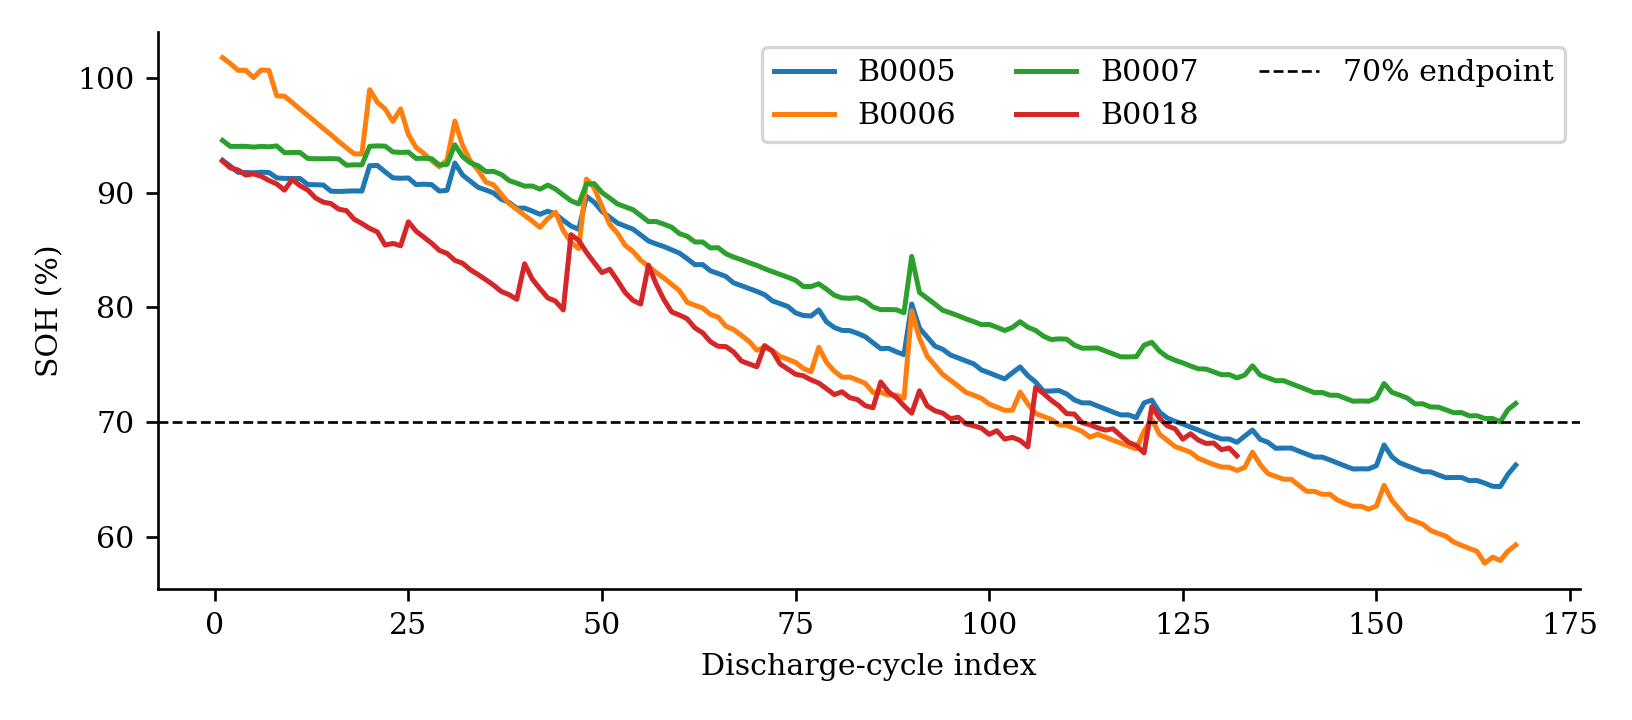

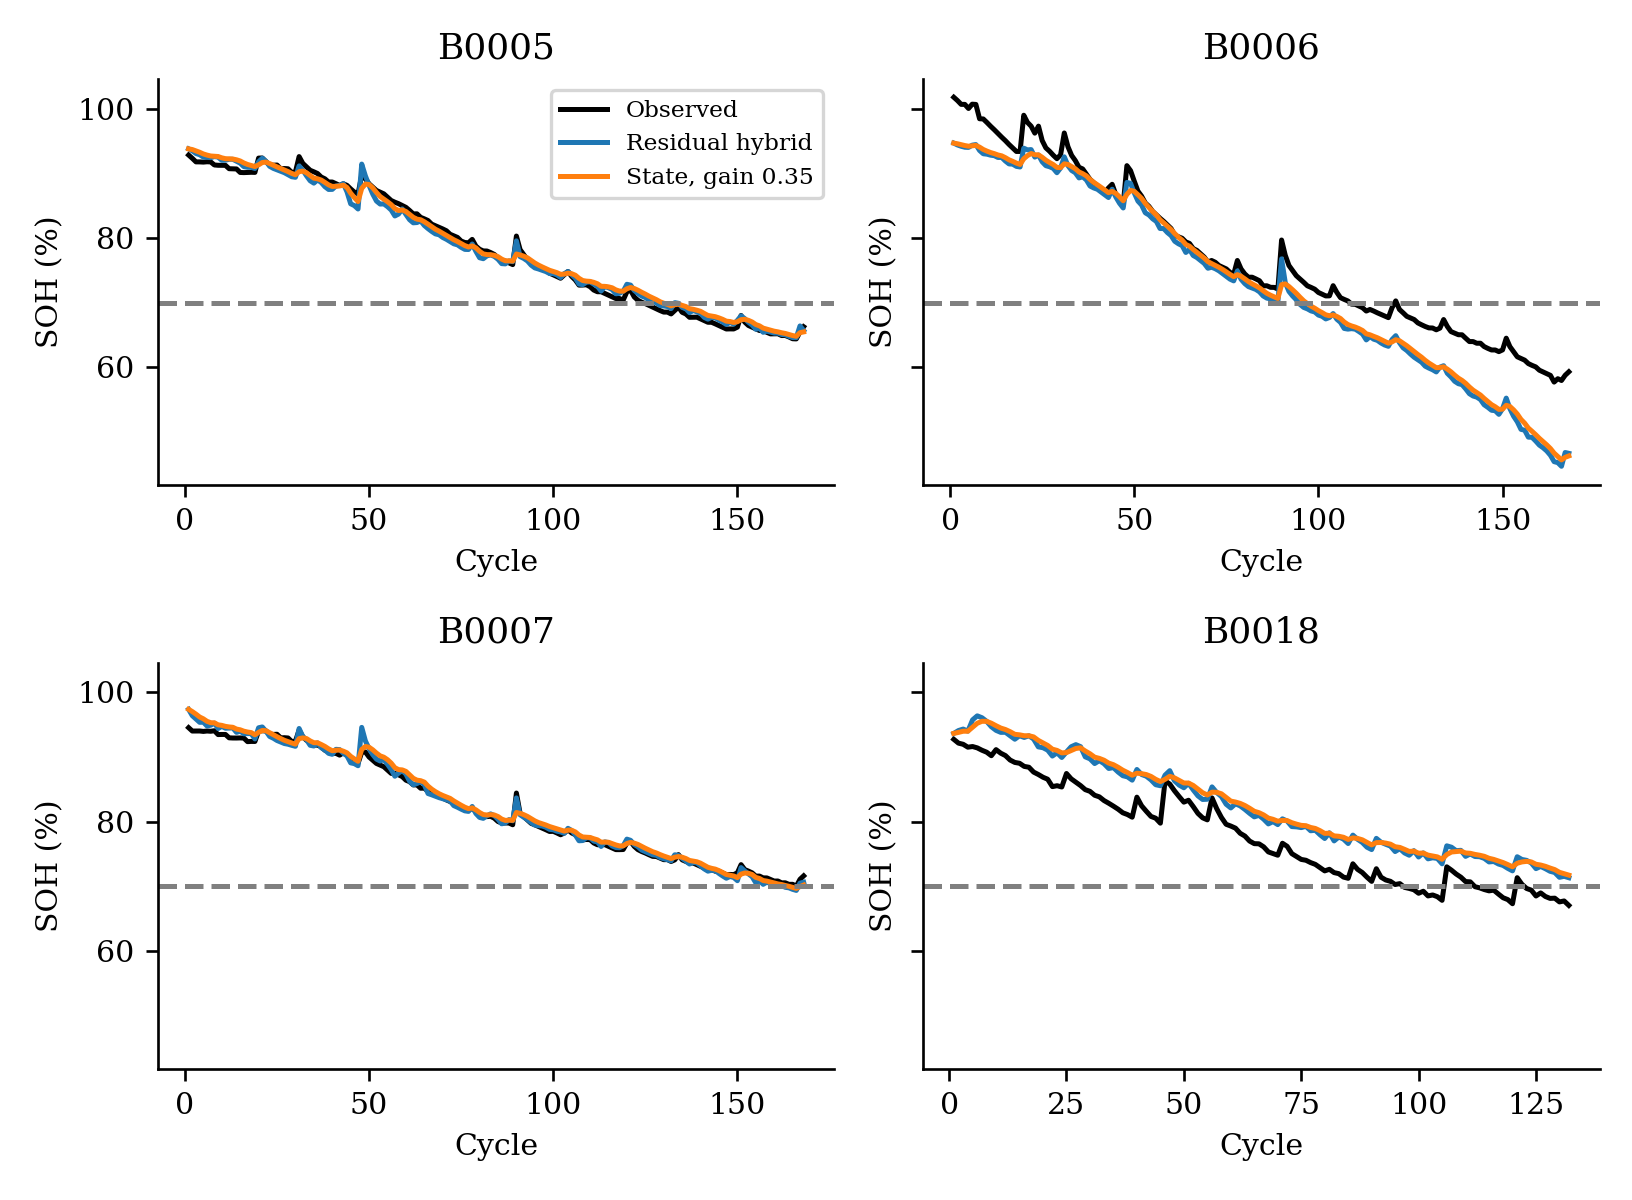

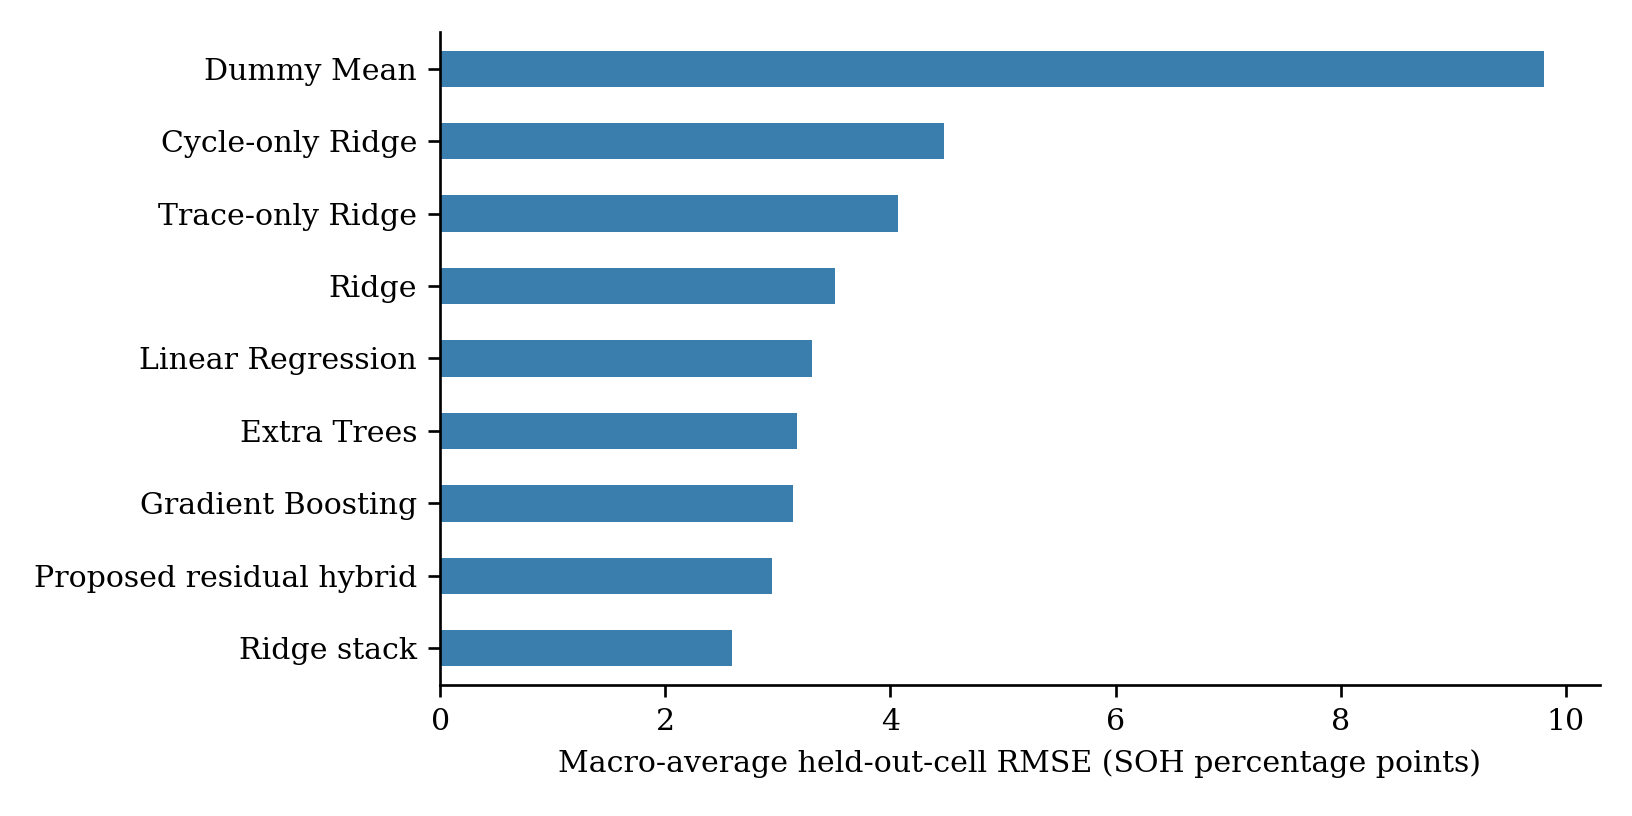

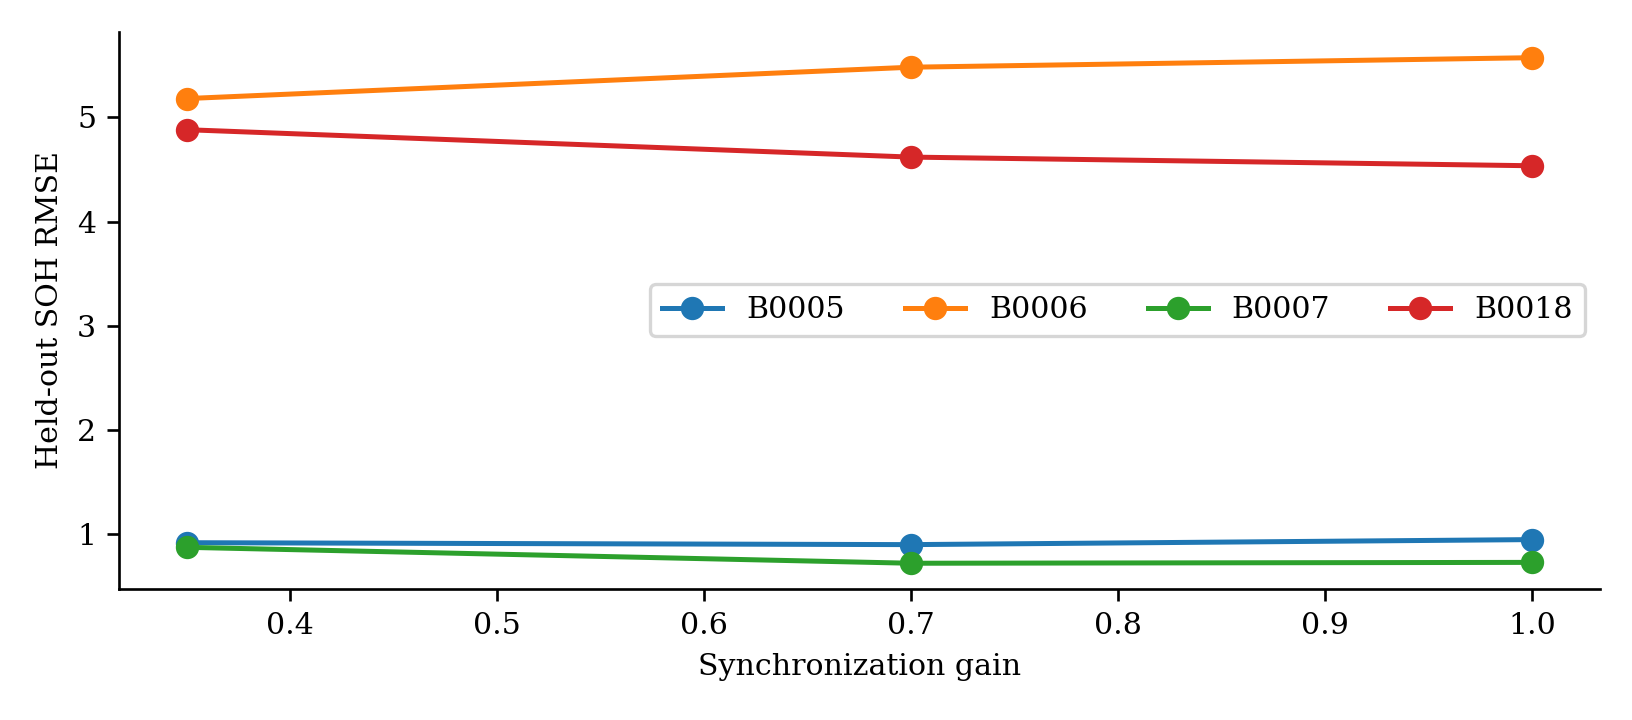

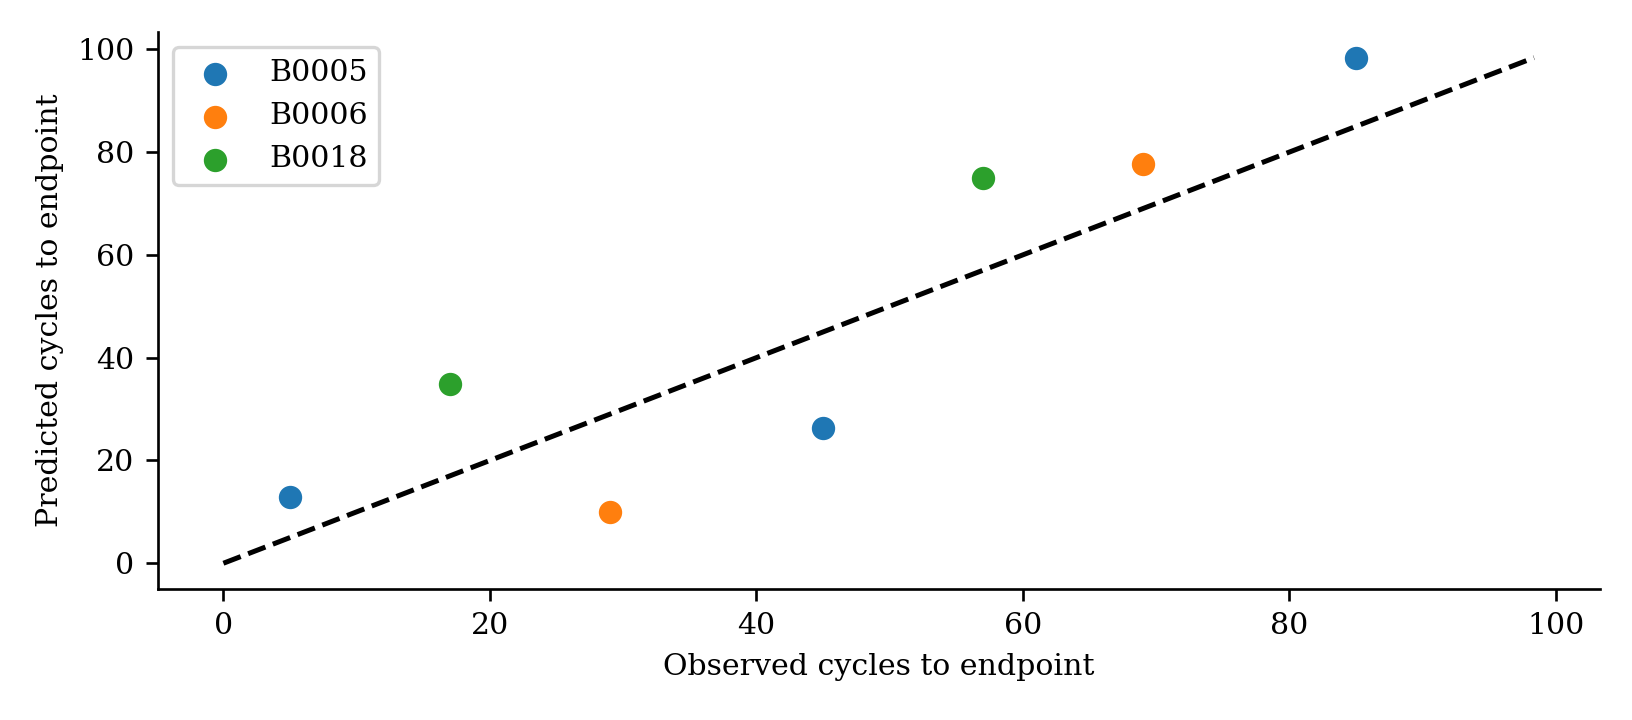

In [4]:
from IPython.display import display, Image
for name in ['fig1_trajectories.png','fig2_heldout.png','fig3_comparison.png','fig4_gain.png','fig5_rul.png']:
    display(Image(filename=str(OUT/name)))


## Interpretation and limits
The residual hybrid has macro MAE 2.548 and RMSE 2.948; Ridge stacking is best on macro RMSE at 2.592. The residual method improves RMSE over Ridge and Linear Regression but has higher MAE than Linear Regression. Gain 0.35 reduces residual-hybrid roughness by 81.64% and slightly worsens clean RMSE. It misses the B0018 endpoint and produces an unsupported B0007 endpoint alarm. RUL MAE is 14.82 cycles at seven uncensored origins. Only four cells and three observed endpoints are available; results do not establish broad field generalization. The primary interval experiment from the Kaggle draft is not transferred to NASA: calibrated prediction intervals are not claimed here.

Dataset citation: B. Saha and K. Goebel (2007), Battery Data Set, NASA Prognostics Data Repository. Official source: https://www.nasa.gov/intelligent-systems-division/discovery-and-systems-health/pcoe/pcoe-data-set-repository/
